# Pan-cancer scores

The pooled ROC cells score the UNI2 A2 `best_mlp` on every section of the seven training cohorts in `section_index.csv` (BRCA, CRC, GBM, GIST, HCC, Lung, PDAC). The weight is `data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt` (fold 1; adjacent loss, L2 to L1 NLL weight 2, spatial k=8 mean, no gate). Predictions are `pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/`. A matched cell is a nucleus that has a ground-truth label. One weight is applied to all 896 sections, including sections it trained on, so this AUROC is higher than performance on a new slide.

The paired_v2 UNI2 A0–A3 retrain, including the held-out pooled OOF L2 macro AUROC, stays in `2_Pred_statistic_visual_pancancer_uni2_ablation.ipynb`.

The held-out comparison of the same weights, pooled out-of-fold L2 macro AUROC, stays in `2_Pred_statistic_visual_pancancer_uni2_ablation.ipynb`.

Matched-cell AUROC uses labeled nuclei only. It is separate from an all-nuclei StarDist map.


In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import pandas as pd

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
PKG = REPO / "code" / "Hist2Pheno_pkg"
PAN = REPO / "code" / "PanCancer"
for p in (PKG, PAN):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from uni_label_cv_helpers import plot_pooled_stardist_tier_rocs

PRED = REPO / "data" / "PanCancer" / "pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment"
ROC_ROOT = PRED / "stardist_roc"
OUT = PRED / "pooled_roc"
OUT.mkdir(parents=True, exist_ok=True)
print("ROC_ROOT", ROC_ROOT, "exists", ROC_ROOT.is_dir())
print("n sample dirs", len(list(ROC_ROOT.glob("*"))) if ROC_ROOT.is_dir() else 0)

met = PRED / "metrics_per_section.csv"
if met.is_file():
    df = pd.read_csv(met)
    print(df.groupby("dataset")[["macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]].mean())
    display(df.head())

ROC_ROOT /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/stardist_roc exists True
n sample dirs 896
         macro_auc_L1_cells  macro_auc_L12_cells  macro_auc_L2_cells
dataset                                                             
BRCA               0.899171             0.883411            0.866280
CRC                0.715898             0.774970            0.753159
GBM                0.603886             0.651664            0.643578
GIST               0.694473             0.668628            0.662767
HCC                0.811962             0.790133            0.765253
Lung               0.713092             0.720226            0.708331
PDAC               0.822474             0.807218            0.763388


,section_id,evaluation_scope,checkpoint_sha256,run_id,requested_native_col,native_col_used,mapping_sha256,model_family,scaler_sha256,embedder,...,n_matched,n_stardist_all,macro_auc_L1,macro_auc_L12,macro_auc_L2,panel,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells,execution_id
0,Lung::THD0008,deployment_not_oof,e6d4beb2d413feabb7f26778eb48d74d20c8120b18b4f1...,7e29f630be4927ea84d5ae9d97b478c934e8ffe1b7dfce...,final_CT,final_CT,059471c5e8b45d5f00c84b064830fc4a0257d66d3d1f2c...,496401e4cdd872782b279da7f9838d182e50caac2d67d1...,2a182371182f99dd652e70816690b0609bb98dc023ee7a...,uni2,...,34402,113389,NaN,NaN,NaN,NaN,0.589277,0.612113,0.621532,20261102T203341.846685Z_a0de8c4e
1,Lung::THD0011,deployment_not_oof,e6d4beb2d413feabb7f26778eb48d74d20c8120b18b4f1...,1b2569f53496eb95b6a981a9591444047ed11a1a001d1c...,final_CT,final_CT,059471c5e8b45d5f00c84b064830fc4a0257d66d3d1f2c...,496401e4cdd872782b279da7f9838d182e50caac2d67d1...,2a182371182f99dd652e70816690b0609bb98dc023ee7a...,uni2,...,22034,56677,NaN,NaN,NaN,NaN,0.622095,0.634120,0.632998,20261102T203341.846685Z_a0de8c4e
2,Lung::TILD117LA,deployment_not_oof,e6d4beb2d413feabb7f26778eb48d74d20c8120b18b4f1...,03b0e6d117188c5cd2685ae185b242a4b79b2cf8a78ffe...,final_CT,final_CT,059471c5e8b45d5f00c84b064830fc4a0257d66d3d1f2c...,496401e4cdd872782b279da7f9838d182e50caac2d67d1...,2a182371182f99dd652e70816690b0609bb98dc023ee7a...,uni2,...,9304,75608,NaN,NaN,NaN,NaN,0.799979,0.819382,0.799502,20261102T203341.846685Z_a0de8c4e
3,Lung::TILD117MA1,deployment_not_oof,e6d4beb2d413feabb7f26778eb48d74d20c8120b18b4f1...,5591e4b6d7557336a5c22e88e6cb5916fbf26a0fcee89f...,final_CT,final_CT,059471c5e8b45d5f00c84b064830fc4a0257d66d3d1f2c...,496401e4cdd872782b279da7f9838d182e50caac2d67d1...,2a182371182f99dd652e70816690b0609bb98dc023ee7a...,uni2,...,8004,121456,NaN,NaN,NaN,NaN,0.857344,0.841945,0.822448,20261102T203341.846685Z_a0de8c4e
4,Lung::TILD175MA,deployment_not_oof,e6d4beb2d413feabb7f26778eb48d74d20c8120b18b4f1...,d23e5722dd977a7f86b59dd6ad9aa8d10db28157b37235...,final_CT,final_CT,059471c5e8b45d5f00c84b064830fc4a0257d66d3d1f2c...,496401e4cdd872782b279da7f9838d182e50caac2d67d1...,2a182371182f99dd652e70816690b0609bb98dc023ee7a...,uni2,...,14132,72654,NaN,NaN,NaN,NaN,0.896374,0.897488,0.864778,20261102T203341.846685Z_a0de8c4e


## Pooled ROC (matched cells, UNI2 A2, pan-cancer L1 / L12 / L2)

Uses the same CSV layout as cohort StarDist AUROC tables so `plot_pooled_stardist_tier_rocs` can concatenate all sections.



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

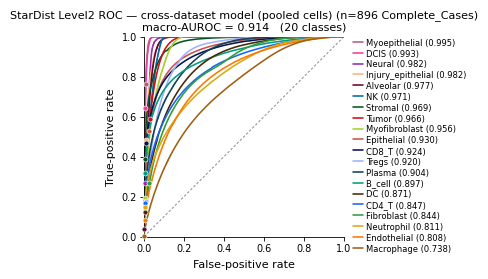

Pooled macro AUROC (L2): 0.9142

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6

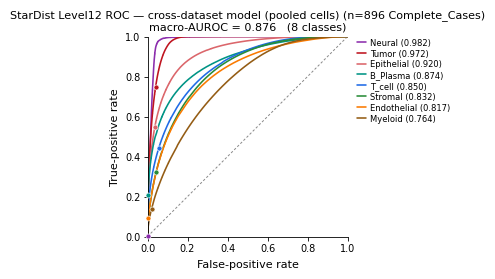

Pooled macro AUROC (L12): 0.8765

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,

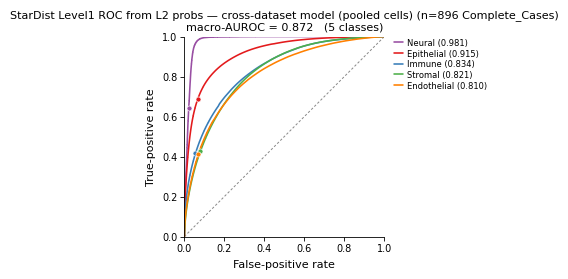

Pooled macro AUROC (L1): 0.8721
pooled L2 macro AUROC = 0.9142
pooled L12 macro AUROC = 0.8765
pooled L1 macro AUROC = 0.8721


In [2]:
if not ROC_ROOT.is_dir() or not any(ROC_ROOT.iterdir()):
    raise FileNotFoundError(
        f"No per-section AUROC CSVs under {ROC_ROOT}. "
        "Run code/PanCancer/PanCancer_predict_visualize.py first."
    )

results = plot_pooled_stardist_tier_rocs(
    ROC_ROOT,
    OUT,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(2.0, 2.0),
    show_barplot=False,
    save_per_class_csv=True,
    show=True,
)
for tier, rec in results.items():
    info = rec.get("roc_info") or {}
    print(f"pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")

## Hold-out cancers (Prostate and others under `data/`)

UNI2 A2 weight: `data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt`

| Folder | Status |
|--------|--------|
| `data/ST/Prostate` | HE + StarDist; **no** `{sample}_matched_features.h5ad` yet |
| `data/Visium/Prostate` | Visium counts; needs HE alignment + UNI + h5ad |

Apply the UNI2 A2 checkpoint only after a matched UNI2 h5ad exists, then:

```bash
python -u code/PanCancer/PanCancer_predict_visualize.py \
  --checkpoint data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt \
  --embedder uni2 \
  --index-csv /path/to/prostate_section_index.csv
```

Native labels (if any) should map through `celltype_pancancer` aliases, or leave GT empty and only inspect StarDist-all spatial maps.


## Removed: cell-stratified UNI and the pre-fix UNI2 predictions

`result_cell_stratified_spatial/`, `pred_cell_stratified_spatial/`, and `result_smoke_cellstrat/` were the cell-type split of the older UNI model. Cells from the same section could sit in both train and validation, and that run used the code that had the bug.

Also removed: `data/Visium/HCC/pred_uni2_A3_bestmlp`, `data/Visium/CRC/pred_uni2_A3_bestmlp` (no `paired_v2` suffix; those weights were deleted), the 2026-10-26 figures in `uni2_ablation_compare/`, and the leftover `pred_uni2_A2_bestmlp_paired_v2_seed42/` unlabeled folder. The current UNI2 A2 deployment is `pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/`.


## A2 best weights on all training sections

One `best_mlp_gpu.pt` per encoder, scored on every section in `section_index.csv`. This is the deployment prediction from `pred_uni_A2.sh`, `pred_virchow2_A2.sh`, and `3_demo_pred.sh uni2 A2`. It is not the five-fold OOF score.

| Encoder | Prediction directory |
| --- | --- |
| UNI | `pred_uni_A2_deployment` |
| Virchow2 | `pred_virchow2_A2_deployment` |
| UNI2 | `pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment` |

A directory with no finished sections is skipped. A run that has not reached all 896 sections is shown with its finished count.


Training index: 896 sections across Lung, BRCA, CRC, HCC, PDAC, GIST, GBM
UNI: 896/896 training sections
Virchow2: 896/896 training sections
UNI2: 896/896 training sections


,encoder,label,n_sections,n_expected,n_matched,n_sections_without_stardist,mean_section_L1,mean_section_L12,mean_section_L2,cell_weighted_L2,mean_of_cancer_L2
0,UNI,UNI A2,896,896,5627071,0,0.757236,0.734126,0.713020,0.746733,0.751659
1,Virchow2,Virchow2 A2,896,896,5627071,0,0.751765,0.729534,0.708368,0.741949,0.746507
2,UNI2,UNI2 A2,896,896,5627071,0,0.739754,0.718747,0.700089,0.729745,0.737536


Highest mean section L2 on finished training sections: UNI 0.7130 (896/896 sections). These sections include the ones used to train the weight.


,dataset,n_index,UNI_n,UNI,Virchow2_n,Virchow2,UNI2_n,UNI2,best
0,BRCA,2,2,0.884164,2,0.880520,2,0.866280,UNI
1,CRC,3,3,0.779960,3,0.767422,3,0.753159,UNI
2,GBM,2,2,0.642715,2,0.642946,2,0.643578,UNI2
3,GIST,550,550,0.677229,550,0.671403,550,0.662767,UNI
4,HCC,36,36,0.773931,36,0.772729,36,0.765253,UNI
5,Lung,25,25,0.730713,25,0.719800,25,0.708331,UNI
6,PDAC,278,278,0.772903,278,0.770732,278,0.763388,UNI


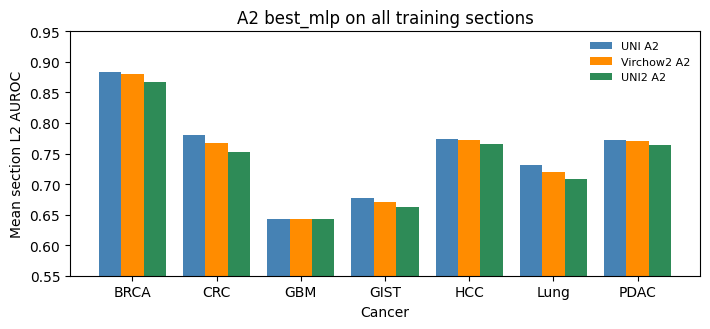

In [3]:
import matplotlib.pyplot as plt
import numpy as np

PAN_DATA = REPO / "data" / "PanCancer"
OUT_A2 = PAN_DATA / "embedder_A2_compare"
OUT_A2.mkdir(parents=True, exist_ok=True)

A2_DEPLOY = {
    "UNI": {
        "label": "UNI A2",
        "color": "steelblue",
        "pred": PAN_DATA / "pred_uni_A2_deployment",
    },
    "Virchow2": {
        "label": "Virchow2 A2",
        "color": "darkorange",
        "pred": PAN_DATA / "pred_virchow2_A2_deployment",
    },
    "UNI2": {
        "label": "UNI2 A2",
        "color": "seagreen",
        "pred": PAN_DATA / "pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment",
    },
}

index = pd.read_csv(PAN_DATA / "section_index.csv")
expected = index[["section_id", "dataset", "sample"]].drop_duplicates("section_id")
n_expected = int(expected["section_id"].nunique())
print(
    f"Training index: {n_expected} sections across "
    f"{', '.join(expected['dataset'].drop_duplicates().tolist())}"
)

AUC = {
    "L1": "macro_auc_L1_cells",
    "L12": "macro_auc_L12_cells",
    "L2": "macro_auc_L2_cells",
}

frames = []
for key, spec in A2_DEPLOY.items():
    path = spec["pred"] / "metrics_per_section.csv"
    if not path.is_file():
        print(f"{key}: prediction not started ({spec['pred'].name})")
        continue
    raw = pd.read_csv(path)
    if raw.empty or "section_id" not in raw.columns:
        print(f"{key}: metrics file has no finished sections yet")
        continue
    missing_cols = [col for col in ("dataset", *AUC.values()) if col not in raw.columns]
    if missing_cols:
        print(f"{key}: metrics missing {missing_cols}")
        continue
    if "evaluation_scope" in raw.columns:
        raw = raw.loc[raw["evaluation_scope"].astype(str) == "deployment_not_oof"].copy()
    keep = ["section_id", "dataset", *AUC.values()]
    for col in ("sample", "n_matched", "n_stardist_all"):
        if col in raw.columns:
            keep.append(col)
    got = raw[keep].drop_duplicates("section_id")
    n_raw = int(got["section_id"].nunique())
    got = got.merge(expected[["section_id"]], on="section_id", how="inner")
    print(f"{key}: {got['section_id'].nunique()}/{n_expected} training sections")
    outside = n_raw - int(got["section_id"].nunique())
    if outside:
        print(f"{key}: {outside} metric rows are outside section_index.csv and were left out")
    if got.empty:
        continue
    got.insert(0, "encoder", key)
    got.insert(1, "label", spec["label"])
    frames.append(got)

if not frames:
    raise FileNotFoundError("No A2 deployment metrics yet for UNI, Virchow2, or UNI2")

sections = pd.concat(frames, ignore_index=True)
sections.to_csv(OUT_A2 / "a2_deployment_sections.csv", index=False)

ready = [key for key in A2_DEPLOY if (sections["encoder"] == key).any()]
rows = []
for key in ready:
    sub = sections.loc[sections["encoder"] == key]
    weights = sub["n_matched"] if "n_matched" in sub.columns else None
    row = {
        "encoder": key,
        "label": A2_DEPLOY[key]["label"],
        "n_sections": int(sub["section_id"].nunique()),
        "n_expected": n_expected,
        "n_matched": int(weights.sum()) if weights is not None else pd.NA,
        "n_sections_without_stardist": (
            int((sub["n_stardist_all"] == 0).sum()) if "n_stardist_all" in sub.columns else pd.NA
        ),
    }
    for name, col in AUC.items():
        row[f"mean_section_{name}"] = float(sub[col].mean())
    if weights is not None and weights.notna().all() and float(weights.sum()) > 0:
        row["cell_weighted_L2"] = float(np.average(sub[AUC["L2"]], weights=weights))
    else:
        row["cell_weighted_L2"] = pd.NA
    row["mean_of_cancer_L2"] = float(sub.groupby("dataset")[AUC["L2"]].mean().mean())
    rows.append(row)

summary = pd.DataFrame(rows).sort_values("mean_section_L2", ascending=False)
display(summary)
summary.to_csv(OUT_A2 / "a2_deployment_overall.csv", index=False)
winner = summary.iloc[0]
print(
    f"Highest mean section L2 on finished training sections: {winner.encoder} "
    f"{float(winner.mean_section_L2):.4f} ({int(winner.n_sections)}/{n_expected} sections). "
    "These sections include the ones used to train the weight."
)

order = ["BRCA", "CRC", "GBM", "GIST", "HCC", "Lung", "PDAC"]
by_dataset = expected.groupby("dataset").size().rename("n_index").reindex(order).to_frame()
for key in ready:
    sub = sections.loc[sections["encoder"] == key]
    grouped = sub.groupby("dataset").agg(**{
        f"{key}_n": ("section_id", "size"),
        key: (AUC["L2"], "mean"),
    })
    by_dataset = by_dataset.join(grouped, how="left")
by_dataset["best"] = by_dataset[ready].idxmax(axis=1)
display(by_dataset.reset_index())
by_dataset.reset_index().to_csv(OUT_A2 / "a2_deployment_by_cancer.csv", index=False)

n_enc = len(ready)
width = 0.8 / n_enc
fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(len(by_dataset))
for i, key in enumerate(ready):
    ax.bar(
        x + (i - (n_enc - 1) / 2) * width,
        by_dataset[key].to_numpy(),
        width=width,
        label=A2_DEPLOY[key]["label"],
        color=A2_DEPLOY[key]["color"],
    )
ax.set_xticks(x)
ax.set_xticklabels(by_dataset.index.tolist())
ax.set_xlabel("Cancer")
ax.set_ylabel("Mean section L2 AUROC")
ax.set_ylim(0.55, 0.95)
ax.set_title("A2 best_mlp on all training sections")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(OUT_A2 / "a2_deployment_l2_by_cancer.pdf", dpi=150, bbox_inches="tight")
plt.show()
